In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# cleaned dataset
df = pd.read_csv("../data/cleaned_employee_data.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [2]:
model_df = df.copy()

print("Original shape:", df.shape)
print("copy shape:", model_df.shape)

Original shape: (1470, 35)
copy shape: (1470, 35)


In [3]:
columns_to_drop = [
    'EmployeeNumber',
    'EmployeeCount',
    'StandardHours',
    'Over18'
]

model_df.drop(columns=columns_to_drop, inplace=True)

In [4]:
print("Shape after removing columns:", model_df.shape)

Shape after removing columns: (1470, 31)


In [5]:
X = model_df.drop(columns=['Attrition'])

y = model_df['Attrition']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1470, 30)
y shape: (1470,)


In [6]:
# getting categorical and numerical cols

categorical_cols = X.select_dtypes(
    include=['object']
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

print("Categorical columns:", categorical_cols)
print("\nNumerical columns:", numerical_cols)

Categorical columns: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']

Numerical columns: ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [8]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training features: (1176, 30)
Testing features: (294, 30)

Training target distribution:
Attrition
No     83.843537
Yes    16.156463
Name: proportion, dtype: float64

Testing target distribution:
Attrition
No     84.013605
Yes    15.986395
Name: proportion, dtype: float64


# Encoding and Scaling

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

In [10]:
numeric_transformer = Pipeline(
    steps=[
        ('scaler', StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]
)


preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

In [11]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

Training data shape: (1176, 51)
Testing data shape: (294, 51)


# Training and Testing

# dummy classifier

In [12]:

from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

baseline_model = DummyClassifier(strategy='most_frequent')

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

In [13]:
print("Baseline Accuracy:",
      accuracy_score(y_test, baseline_predictions))

print("\nClassification Report:")
print(classification_report(y_test, baseline_predictions, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, baseline_predictions))

Baseline Accuracy: 0.8401360544217688

Classification Report:
              precision    recall  f1-score   support

          No       0.84      1.00      0.91       247
         Yes       0.00      0.00      0.00        47

    accuracy                           0.84       294
   macro avg       0.42      0.50      0.46       294
weighted avg       0.71      0.84      0.77       294


Confusion Matrix:
[[247   0]
 [ 47   0]]


# Logistic Regression

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logistic_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

In [15]:
logistic_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [16]:
y_pred = logistic_model.predict(X_test)

y_prob = logistic_model.predict_proba(X_test)[:, 1]

In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, pos_label='Yes'))
print("Recall:", recall_score(y_test, y_pred, pos_label='Yes'))
print("F1 Score:", f1_score(y_test, y_pred, pos_label='Yes'))
print("ROC-AUC:", roc_auc_score(
    (y_test == 'Yes').astype(int),
    y_prob
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8605442176870748
Precision: 0.6153846153846154
Recall: 0.3404255319148936
F1 Score: 0.4383561643835616
ROC-AUC: 0.8115255405289

Classification Report:
              precision    recall  f1-score   support

          No       0.88      0.96      0.92       247
         Yes       0.62      0.34      0.44        47

    accuracy                           0.86       294
   macro avg       0.75      0.65      0.68       294
weighted avg       0.84      0.86      0.84       294


Confusion Matrix:
[[237  10]
 [ 31  16]]


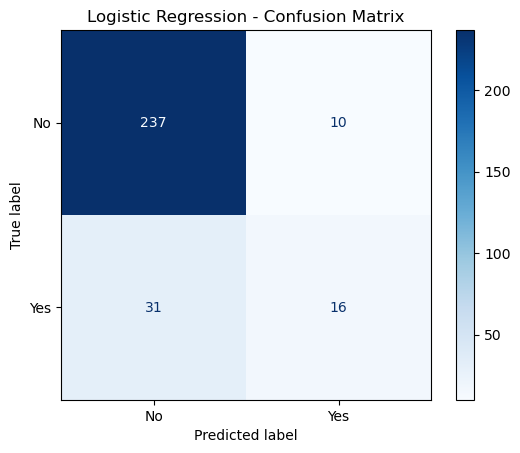

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=['No', 'Yes'],
    cmap='Blues'
)

plt.title('Logistic Regression - Confusion Matrix')
plt.show()

In [19]:
comparison = pd.DataFrame({
    'Model': ['Baseline', 'Logistic Regression'],
    'Accuracy': [
        accuracy_score(y_test, baseline_predictions),
        accuracy_score(y_test, y_pred)
    ],
    'Precision': [
        precision_score(y_test, baseline_predictions, pos_label='Yes', zero_division=0),
        precision_score(y_test, y_pred, pos_label='Yes', zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, baseline_predictions, pos_label='Yes', zero_division=0),
        recall_score(y_test, y_pred, pos_label='Yes', zero_division=0)
    ],
    'F1 Score': [
        f1_score(y_test, baseline_predictions, pos_label='Yes', zero_division=0),
        f1_score(y_test, y_pred, pos_label='Yes', zero_division=0)
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Baseline,0.840136,0.000000,0.000000,0.000000
1,Logistic Regression,0.860544,0.615385,0.340426,0.438356


# Handling class imbalance

In [20]:
logistic_balanced = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(
            class_weight='balanced',
            max_iter=1000,
            random_state=42
        ))
    ]
)

In [21]:
logistic_balanced.fit(X_train, y_train)

y_pred_balanced = logistic_balanced.predict(X_test)

y_prob_balanced = logistic_balanced.predict_proba(X_test)[:, 1]

In [22]:
print(classification_report(
    y_test,
    y_pred_balanced,
    labels=['No', 'Yes']
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred_balanced,
    labels=['No', 'Yes']
))

print("ROC-AUC:",
      roc_auc_score(
          (y_test == 'Yes').astype(int),
          y_prob_balanced
      ))

              precision    recall  f1-score   support

          No       0.92      0.77      0.84       247
         Yes       0.35      0.64      0.45        47

    accuracy                           0.75       294
   macro avg       0.63      0.71      0.65       294
weighted avg       0.83      0.75      0.78       294

Confusion Matrix:
[[191  56]
 [ 17  30]]
ROC-AUC: 0.8031699543457662


In [23]:
comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Logistic Regression Balanced'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_balanced)
    ],
    'Precision': [
        precision_score(y_test, y_pred, pos_label='Yes', zero_division=0),
        precision_score(y_test, y_pred_balanced, pos_label='Yes', zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, y_pred, pos_label='Yes', zero_division=0),
        recall_score(y_test, y_pred_balanced, pos_label='Yes', zero_division=0)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred, pos_label='Yes', zero_division=0),
        f1_score(y_test, y_pred_balanced, pos_label='Yes', zero_division=0)
    ],
    'ROC-AUC': [
        roc_auc_score((y_test == 'Yes').astype(int), y_prob),
        roc_auc_score((y_test == 'Yes').astype(int), y_prob_balanced)
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.860544,0.615385,0.340426,0.438356,0.811526
1,Logistic Regression Balanced,0.751701,0.348837,0.638298,0.451128,0.803170


# Decision Trees

In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

tree_preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
        ('num', 'passthrough', numerical_cols)
    ]
)

In [26]:
decision_tree = Pipeline(
    steps=[
        ('preprocessor', tree_preprocessor),
        ('classifier', DecisionTreeClassifier(
            random_state=42,
            class_weight='balanced'
        ))
    ]
)

In [27]:
decision_tree.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...), ('num', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [28]:
y_pred_tree = decision_tree.predict(X_test)

y_prob_tree = decision_tree.predict_proba(X_test)[:, 1]

In [29]:
print("Classification Report:")
print(classification_report(y_test, y_pred_tree))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred_tree,
    labels=['No', 'Yes']
))

print("ROC-AUC:",
      roc_auc_score(
          (y_test == 'Yes').astype(int),
          y_prob_tree
      ))

Classification Report:
              precision    recall  f1-score   support

          No       0.86      0.88      0.87       247
         Yes       0.29      0.26      0.27        47

    accuracy                           0.78       294
   macro avg       0.57      0.57      0.57       294
weighted avg       0.77      0.78      0.77       294

Confusion Matrix:
[[217  30]
 [ 35  12]]
ROC-AUC: 0.5669308295288138


In [30]:
# checking is overfitting ?

from sklearn.metrics import accuracy_score, recall_score

# Training predictions
y_train_pred_tree = decision_tree.predict(X_train)

# Testing predictions
y_test_pred_tree = decision_tree.predict(X_test)

print("Training Accuracy:",
      accuracy_score(y_train, y_train_pred_tree))

print("Testing Accuracy:",
      accuracy_score(y_test, y_test_pred_tree))

print("Training Recall:",
      recall_score(y_train, y_train_pred_tree, pos_label='Yes'))

print("Testing Recall:",
      recall_score(y_test, y_test_pred_tree, pos_label='Yes'))

Training Accuracy: 1.0
Testing Accuracy: 0.7789115646258503
Training Recall: 1.0
Testing Recall: 0.2553191489361702


# Random forest

In [31]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

random_forest = Pipeline(
    steps=[
        ('preprocessor', tree_preprocessor),
        ('classifier', RandomForestClassifier(
            n_estimators=300,
            class_weight='balanced',
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [32]:
random_forest.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...), ('num', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [33]:
y_pred_rf = random_forest.predict(X_test)

y_prob_rf = random_forest.predict_proba(X_test)[:, 1]

In [34]:
print("Classification Report:")
print(classification_report(y_test, y_pred_rf))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf, labels=['No', 'Yes']))

print("ROC-AUC:",
      roc_auc_score((y_test == 'Yes').astype(int), y_prob_rf))

Classification Report:
              precision    recall  f1-score   support

          No       0.85      0.98      0.91       247
         Yes       0.56      0.11      0.18        47

    accuracy                           0.84       294
   macro avg       0.70      0.55      0.55       294
weighted avg       0.81      0.84      0.80       294

Confusion Matrix:
[[243   4]
 [ 42   5]]
ROC-AUC: 0.7877508829356534


In [35]:
y_train_pred_rf = random_forest.predict(X_train)

print("Training Accuracy:",
      accuracy_score(y_train, y_train_pred_rf))

print("Testing Accuracy:",
      accuracy_score(y_test, y_pred_rf))

print("Training Recall:",
      recall_score(y_train, y_train_pred_rf, pos_label='Yes'))

print("Testing Recall:",
      recall_score(y_test, y_pred_rf, pos_label='Yes'))

Training Accuracy: 1.0
Testing Accuracy: 0.8435374149659864
Training Recall: 1.0
Testing Recall: 0.10638297872340426


# Xgboost

In [36]:
!pip install xgboost

In [37]:
from xgboost import XGBClassifier

In [38]:
y_train_xgb = y_train.map({'No': 0, 'Yes': 1})
y_test_xgb = y_test.map({'No': 0, 'Yes': 1})

class_counts = y_train_xgb.value_counts()

scale_weight = class_counts[0] / class_counts[1]

print("Scale Pos Weight:", scale_weight)

Scale Pos Weight: 5.189473684210526


In [39]:
xgb_model = Pipeline(
    steps=[
        ('preprocessor', tree_preprocessor),

        ('classifier', XGBClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=3,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=scale_weight,
            reg_alpha=0.1,
            reg_lambda=1,
            eval_metric='logloss',
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [40]:
xgb_model.fit(X_train, y_train_xgb)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...), ('num', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [41]:
y_pred_xgb = xgb_model.predict(X_test)

y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

In [42]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    accuracy_score,
    recall_score
)

print("Classification Report:")

print(classification_report(
    y_test_xgb,
    y_pred_xgb,
    target_names=['No', 'Yes']
))

print("Confusion Matrix:")

print(confusion_matrix(
    y_test_xgb,
    y_pred_xgb
))

print("ROC-AUC:",
      roc_auc_score(y_test_xgb, y_prob_xgb))

Classification Report:
              precision    recall  f1-score   support

          No       0.90      0.89      0.90       247
         Yes       0.46      0.51      0.48        47

    accuracy                           0.83       294
   macro avg       0.68      0.70      0.69       294
weighted avg       0.83      0.83      0.83       294

Confusion Matrix:
[[219  28]
 [ 23  24]]
ROC-AUC: 0.7887845637005773


In [43]:
y_train_pred_xgb = xgb_model.predict(X_train)

print("Training Accuracy:",
      accuracy_score(y_train_xgb, y_train_pred_xgb))

print("Testing Accuracy:",
      accuracy_score(y_test_xgb, y_pred_xgb))

print("Training Recall:",
      recall_score(y_train_xgb, y_train_pred_xgb))

print("Testing Recall:",
      recall_score(y_test_xgb, y_pred_xgb))

Training Accuracy: 0.9702380952380952
Testing Accuracy: 0.826530612244898
Training Recall: 0.9736842105263158
Testing Recall: 0.5106382978723404


# improving using Gridsearchcv

In [44]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer

In [45]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [46]:
param_grid = {
    'classifier__n_estimators': [200, 400],

    'classifier__learning_rate': [0.03, 0.05],

    'classifier__max_depth': [2, 3, 4],

    'classifier__min_child_weight': [1, 3],

    'classifier__subsample': [0.8, 1.0],

    'classifier__colsample_bytree': [0.8, 1.0],

    'classifier__scale_pos_weight': [4, 5.2]
}

In [47]:
grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    scoring={
        'f1': 'f1',
        'recall': 'recall',
        'precision': 'precision',
        'roc_auc': 'roc_auc'
    },
    refit='f1',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

In [48]:
grid_search.fit(X_train, y_train_xgb)

Fitting 5 folds for each of 192 candidates, totalling 960 fits


,estimator,"Pipeline(step...=None, ...))])"
,param_grid,"{'classifier__colsample_bytree': [0.8, 1.0], 'classifier__learning_rate': [0.03, 0.05], 'classifier__max_depth': [2, 3, ...], 'classifier__min_child_weight': [1, 3], ...}"
,scoring,"{'f1': 'f1', 'precision': 'precision', 'recall': 'recall', 'roc_auc': 'roc_auc'}"
,n_jobs,-1
,refit,'f1'
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('cat', ...), ('num', ...)]"


In [49]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross Validation F1:")
print(grid_search.best_score_)

Best Parameters:
{'classifier__colsample_bytree': 1.0, 'classifier__learning_rate': 0.05, 'classifier__max_depth': 3, 'classifier__min_child_weight': 1, 'classifier__n_estimators': 200, 'classifier__scale_pos_weight': 4, 'classifier__subsample': 0.8}

Best Cross Validation F1:
0.5766749575418306


In [50]:
best_xgb = grid_search.best_estimator_

y_pred_tuned = best_xgb.predict(X_test)

y_prob_tuned = best_xgb.predict_proba(X_test)[:, 1]

In [51]:
print(classification_report(
    y_test_xgb,
    y_pred_tuned,
    target_names=['No', 'Yes']
))

              precision    recall  f1-score   support

          No       0.89      0.89      0.89       247
         Yes       0.42      0.40      0.41        47

    accuracy                           0.82       294
   macro avg       0.65      0.65      0.65       294
weighted avg       0.81      0.82      0.81       294



In [52]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1',
        'ROC-AUC'
    ],

    'Original XGBoost': [
        accuracy_score(y_test_xgb, y_pred_xgb),
        precision_score(y_test_xgb, y_pred_xgb),
        recall_score(y_test_xgb, y_pred_xgb),
        f1_score(y_test_xgb, y_pred_xgb),
        roc_auc_score(y_test_xgb, y_prob_xgb)
    ],

    'Tuned XGBoost': [
        accuracy_score(y_test_xgb, y_pred_tuned),
        precision_score(y_test_xgb, y_pred_tuned),
        recall_score(y_test_xgb, y_pred_tuned),
        f1_score(y_test_xgb, y_pred_tuned),
        roc_auc_score(y_test_xgb, y_prob_tuned)
    ]
})

results

,Metric,Original XGBoost,Tuned XGBoost
0,Accuracy,0.826531,0.816327
1,Precision,0.461538,0.422222
2,Recall,0.510638,0.404255
3,F1,0.484848,0.413043
4,ROC-AUC,0.788785,0.774485


# randomsearchcv

In [53]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform, loguniform

In [54]:
param_distributions = {

    'classifier__n_estimators': randint(150, 701),

    'classifier__learning_rate': loguniform(0.01, 0.2),

    'classifier__max_depth': randint(2, 7),

    'classifier__min_child_weight': randint(1, 8),

    'classifier__gamma': [0, 0.1, 0.2, 0.3, 0.5, 1, 2],

    'classifier__subsample': uniform(0.6, 0.4),

    'classifier__colsample_bytree': uniform(0.6, 0.4),

    'classifier__reg_alpha': [0, 0.01, 0.1, 0.5, 1, 5],

    'classifier__reg_lambda': [0.1, 0.5, 1, 2, 5, 10],

    'classifier__scale_pos_weight': [3, 4, 5, 5.2, 6, 7],

    'classifier__max_delta_step': [0, 1, 3, 5]
}

In [55]:
random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_distributions,
    n_iter=100,
    scoring='f1',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

In [56]:
random_search.fit(X_train, y_train_xgb)

Fitting 5 folds for each of 100 candidates, totalling 500 fits


,estimator,"Pipeline(step...=None, ...))])"
,param_distributions,"{'classifier__colsample_bytree': <scipy.stats....001B30C273750>, 'classifier__gamma': [0, 0.1, ...], 'classifier__learning_rate': <scipy.stats....001B30DD7B230>, 'classifier__max_delta_step': [0, 1, ...], ...}"
,n_iter,100
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [57]:
print("Best Parameters:")

print(random_search.best_params_)

print("\nBest CV F1 Score:")

print(random_search.best_score_)

Best Parameters:
{'classifier__colsample_bytree': np.float64(0.8227051572055719), 'classifier__gamma': 0.1, 'classifier__learning_rate': np.float64(0.023134557603656035), 'classifier__max_delta_step': 5, 'classifier__max_depth': 6, 'classifier__min_child_weight': 6, 'classifier__n_estimators': 559, 'classifier__reg_alpha': 5, 'classifier__reg_lambda': 2, 'classifier__scale_pos_weight': 5, 'classifier__subsample': np.float64(0.6798027709353279)}

Best CV F1 Score:
0.5776261501751698


In [59]:
best_xgb_random = random_search.best_estimator_

y_pred_random = best_xgb_random.predict(X_test)

y_prob_random = best_xgb_random.predict_proba(X_test)[:, 1]



y_train_pred_random = best_xgb_random.predict(X_train)

print("Training Accuracy:",
      accuracy_score(y_train_xgb, y_train_pred_random))

print("Testing Accuracy:",
      accuracy_score(y_test_xgb, y_pred_random))

print("Training Recall:",
      recall_score(y_train_xgb, y_train_pred_random))

print("Testing Recall:",
      recall_score(y_test_xgb, y_pred_random))

Training Accuracy: 0.9795918367346939
Testing Accuracy: 0.8163265306122449
Training Recall: 1.0
Testing Recall: 0.46808510638297873


In [60]:
print(classification_report(
    y_test_xgb,
    y_pred_random,
    target_names=['No', 'Yes']
))

              precision    recall  f1-score   support

          No       0.90      0.88      0.89       247
         Yes       0.43      0.47      0.45        47

    accuracy                           0.82       294
   macro avg       0.66      0.68      0.67       294
weighted avg       0.82      0.82      0.82       294



# using SMOTENC

In [61]:
!pip install imbalanced-learn

In [62]:
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder

from xgboost import XGBClassifier

In [63]:
pre_smote = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),

        ('cat', OrdinalEncoder(
            handle_unknown='use_encoded_value',
            unknown_value=-1
        ), categorical_cols)
    ],
    sparse_threshold=0
)

In [64]:
categorical_indices = list(
    range(len(numerical_cols),
          len(numerical_cols) + len(categorical_cols))
)

In [65]:
smote = SMOTENC(
    categorical_features=categorical_indices,
    sampling_strategy=0.7,
    random_state=42,
    k_neighbors=5
)

In [66]:
post_smote = ColumnTransformer(
    transformers=[
        ('num', 'passthrough',
         list(range(len(numerical_cols)))),

        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_indices)
    ]
)

In [67]:
smotenc_xgb = ImbPipeline(
    steps=[
        ('preprocessor', pre_smote),

        ('smote', smote),

        ('encoder', post_smote),

        ('classifier', XGBClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=3,
            min_child_weight=3,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_alpha=0.1,
            reg_lambda=1,
            scale_pos_weight=1,
            eval_metric='logloss',
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [68]:
smotenc_xgb.fit(X_train, y_train_xgb)

,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [73]:
y_pred_smotenc = smotenc_xgb.predict(X_test)

y_prob_smotenc = smotenc_xgb.predict_proba(X_test)[:, 1]

In [74]:
print(classification_report(
    y_test_xgb,
    y_pred_smotenc,
    target_names=['No', 'Yes']
))

              precision    recall  f1-score   support

          No       0.87      0.97      0.92       247
         Yes       0.63      0.26      0.36        47

    accuracy                           0.86       294
   macro avg       0.75      0.61      0.64       294
weighted avg       0.83      0.86      0.83       294



In [76]:
print(confusion_matrix(
    y_test_xgb,
    y_pred_smotenc
))

[[240   7]
 [ 35  12]]


# LightGBM

In [77]:
!pip install lightgbm

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 22.0 MB/s  0:00:00


In [78]:
from lightgbm import LGBMClassifier
from imblearn.pipeline import Pipeline as ImbPipeline

In [79]:
smotenc_lgbm = ImbPipeline(
    steps=[
        ('preprocessor', pre_smote),

        ('smote', smote),

        ('encoder', post_smote),

        ('classifier', LGBMClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=-1,
            num_leaves=15,
            class_weight=None,
            reg_alpha=0.1,
            reg_lambda=1,
            random_state=42,
            n_jobs=-1,
            verbosity=-1
        ))
    ]
)

In [80]:
smotenc_lgbm.fit(X_train, y_train_xgb)

,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [81]:
y_pred_lgbm = smotenc_lgbm.predict(X_test)

y_prob_lgbm = smotenc_lgbm.predict_proba(X_test)[:, 1]

In [82]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print(classification_report(
    y_test_xgb,
    y_pred_lgbm,
    target_names=['No', 'Yes']
))

              precision    recall  f1-score   support

          No       0.87      0.97      0.92       247
         Yes       0.60      0.26      0.36        47

    accuracy                           0.85       294
   macro avg       0.74      0.61      0.64       294
weighted avg       0.83      0.85      0.83       294



In [88]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    make_scorer,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

from lightgbm import LGBMClassifier
from imblearn.pipeline import Pipeline as ImbPipeline

In [89]:
lgbm_pipeline = ImbPipeline(
    steps=[
        ('preprocessor', pre_smote),
        ('smote', smote),
        ('encoder', post_smote),
        ('classifier', LGBMClassifier(
            random_state=42,
            verbosity=-1,
            n_jobs=1
        ))
    ]
)

In [106]:
param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__learning_rate': [0.03, 0.05],
    'classifier__num_leaves': [7, 15],
    'classifier__max_depth': [-1, 5],
    'classifier__min_child_samples': [10, 20]
}

In [107]:
param_grid['classifier__subsample_freq'] = [1, 5]

In [108]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [109]:
grid_search = GridSearchCV(
    estimator=lgbm_pipeline,
    param_grid=param_grid,
    scoring={
        'f1': make_scorer(f1_score, pos_label=1),
        'precision': 'precision',
        'recall': 'recall',
        'roc_auc': 'roc_auc'
    },
    refit='f1',
    cv=cv,
    verbose=2,
    n_jobs=-1,
    return_train_score=True
)

In [110]:
grid_search.fit(X_train, y_train_xgb)

Fitting 5 folds for each of 64 candidates, totalling 320 fits


,estimator,Pipeline(step...rbosity=-1))])
,param_grid,"{'classifier__learning_rate': [0.03, 0.05], 'classifier__max_depth': [-1, 5], 'classifier__min_child_samples': [10, 20], 'classifier__n_estimators': [100, 200], ...}"
,scoring,"{'f1': make_scorer(f..., pos_label=1), 'precision': 'precision', 'recall': 'recall', 'roc_auc': 'roc_auc'}"
,n_jobs,-1
,refit,'f1'
,cv,StratifiedKFo... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,True
,transformers,"[('num', ...), ('cat', ...)]"


In [111]:
print("Best CV F1:", grid_search.best_score_)

print("\nBest Parameters:")
print(grid_search.best_params_)

Best CV F1: 0.5220032840722496

Best Parameters:
{'classifier__learning_rate': 0.05, 'classifier__max_depth': -1, 'classifier__min_child_samples': 10, 'classifier__n_estimators': 200, 'classifier__num_leaves': 7, 'classifier__subsample_freq': 1}


In [112]:
best_lgbm = grid_search.best_estimator_

In [113]:
y_pred_lgbm = best_lgbm.predict(X_test)

y_prob_lgbm = best_lgbm.predict_proba(X_test)[:, 1]

print(classification_report(
    y_test_xgb,
    y_pred_lgbm,
    target_names=['No', 'Yes']
))

print(confusion_matrix(y_test_xgb, y_pred_lgbm))

print("ROC-AUC:", roc_auc_score(y_test_xgb, y_prob_lgbm))

              precision    recall  f1-score   support

          No       0.88      0.98      0.92       247
         Yes       0.68      0.28      0.39        47

    accuracy                           0.86       294
   macro avg       0.78      0.63      0.66       294
weighted avg       0.85      0.86      0.84       294

[[241   6]
 [ 34  13]]
ROC-AUC: 0.7791368765612887


# Xgboost

In [114]:
from xgboost import XGBClassifier

from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [115]:
y_train_xgb = y_train.map({
    'No': 0,
    'Yes': 1
})

y_test_xgb = y_test.map({
    'No': 0,
    'Yes': 1
})

In [116]:
xgb_model = Pipeline(
    steps=[
        ('preprocessor', tree_preprocessor),

        ('classifier', XGBClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=3,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=scale_weight,
            reg_alpha=0.1,
            reg_lambda=1,
            eval_metric='logloss',
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [117]:
scale_weight = (
    (y_train_xgb == 0).sum() /
    (y_train_xgb == 1).sum()
)

In [118]:
xgb_model.fit(X_train, y_train_xgb)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...), ('num', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [119]:
y_pred_xgb = xgb_model.predict(X_test)

y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

In [120]:
print(classification_report(
    y_test_xgb,
    y_pred_xgb,
    target_names=['No', 'Yes']
))

              precision    recall  f1-score   support

          No       0.90      0.89      0.90       247
         Yes       0.46      0.51      0.48        47

    accuracy                           0.83       294
   macro avg       0.68      0.70      0.69       294
weighted avg       0.83      0.83      0.83       294



In [121]:
cm = confusion_matrix(y_test_xgb, y_pred_xgb)

print(cm)

[[219  28]
 [ 23  24]]


In [122]:
print(
    "ROC-AUC:",
    roc_auc_score(y_test_xgb, y_prob_xgb)
)

ROC-AUC: 0.7887845637005773


In [123]:
xgb_results = {
    'Model': 'Original XGBoost',
    'Accuracy': accuracy_score(y_test_xgb, y_pred_xgb),
    'Precision': precision_score(y_test_xgb, y_pred_xgb),
    'Recall': recall_score(y_test_xgb, y_pred_xgb),
    'F1 Score': f1_score(y_test_xgb, y_pred_xgb),
    'ROC-AUC': roc_auc_score(y_test_xgb, y_prob_xgb)
}

pd.DataFrame([xgb_results])

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Original XGBoost,0.826531,0.461538,0.510638,0.484848,0.788785


# Feature importance

In [140]:
# Extract fitted XGBoost classifier
xgb_classifier = xgb_model.named_steps['classifier']

# Get transformed feature names
feature_names = xgb_model.named_steps['preprocessor'].get_feature_names_out()

# Create feature importance dataframe
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': xgb_classifier.feature_importances_
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
27,cat__OverTime_Yes,0.059743
21,cat__JobRole_Sales Executive,0.059101
35,num__JobLevel,0.046443
26,cat__OverTime_No,0.043454
43,num__StockOptionLevel,0.041604
50,num__YearsWithCurrManager,0.030513
47,num__YearsAtCompany,0.027991
5,cat__Department_Sales,0.025456
32,num__EnvironmentSatisfaction,0.025108
28,num__Age,0.024820


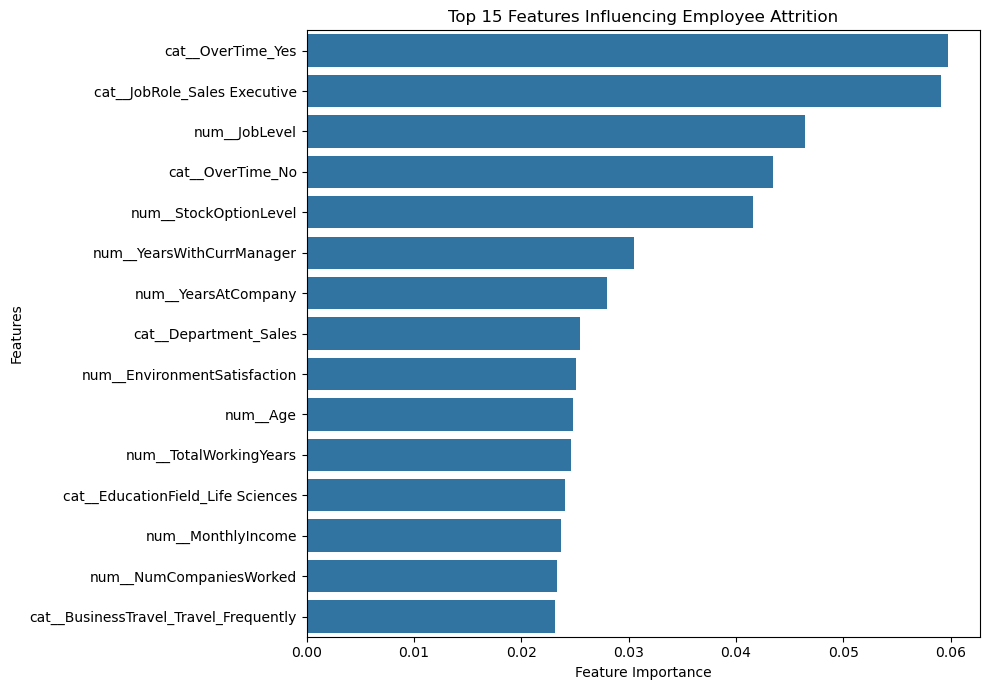

In [141]:
import seaborn as sns
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(15),
    x='Importance',
    y='Feature'
)

plt.title('Top 15 Features Influencing Employee Attrition')
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

# SHAP

In [142]:
!pip install shap

  Using cached shap-0.54.1-cp312-abi3-win_amd64.whl.metadata (23 kB)
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 751.9/751.9 kB 14.8 MB/s  0:00:00

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]



In [144]:
import shap

# Transform test data using the fitted preprocessor
X_test_transformed = xgb_model.named_steps['preprocessor'].transform(X_test)

# Get transformed feature names
feature_names = xgb_model.named_steps['preprocessor'].get_feature_names_out()

# Convert to DataFrame
X_test_transformed_df = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=X_test.index
)

In [145]:
explainer = shap.TreeExplainer(
    xgb_model.named_steps['classifier']
)

shap_values = explainer(X_test_transformed_df)

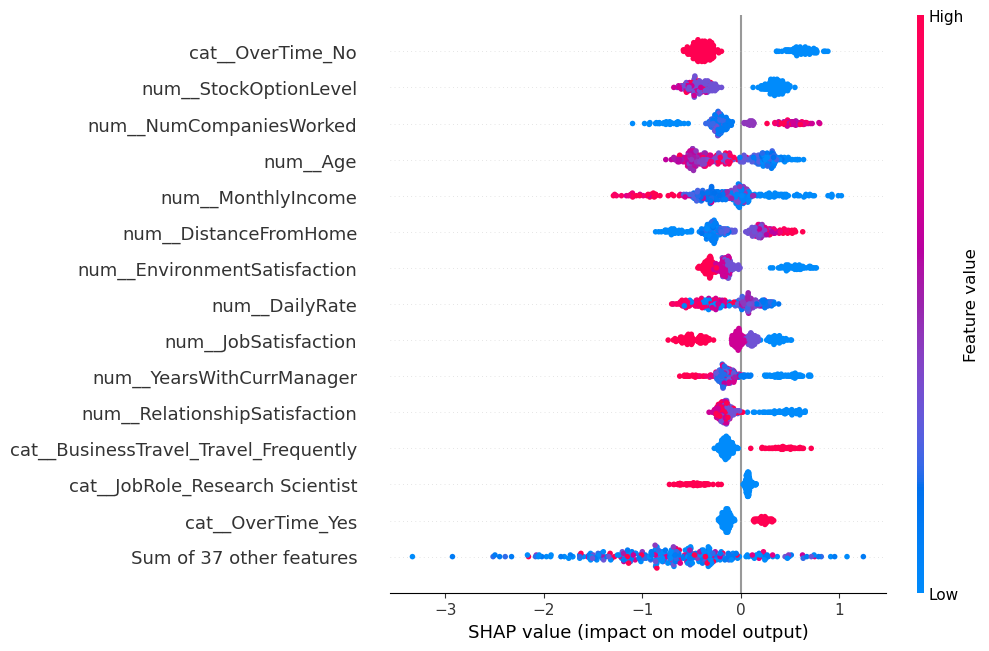

In [146]:
shap.plots.beeswarm(shap_values, max_display=15)

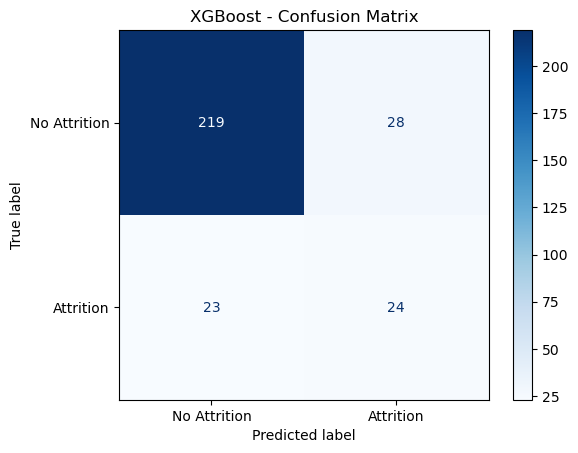

In [148]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    xgb_model,
    X_test,
    y_test_xgb,
    display_labels=['No Attrition', 'Attrition'],
    cmap='Blues'
)

plt.title('XGBoost - Confusion Matrix')
plt.show()

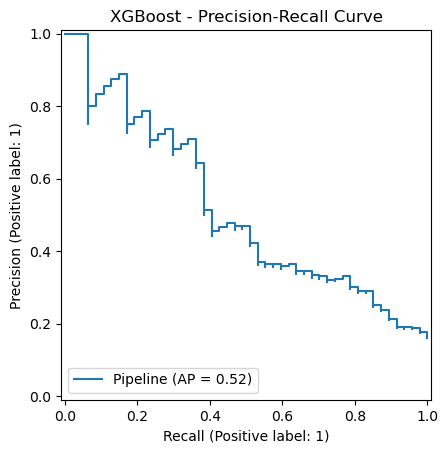

In [149]:
from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_estimator(
    xgb_model,
    X_test,
    y_test_xgb
)

plt.title('XGBoost - Precision-Recall Curve')
plt.show()

In [150]:
df.to_csv(
    "../data/employee_attrition_sql.csv",
    index=False
)

In [152]:
!pip install joblib

# Saving the model

In [153]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    xgb_model,
    "../models/talentpulse_xgboost.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [154]:
loaded_model = joblib.load(
    "../models/talentpulse_xgboost.pkl"
)

predictions = loaded_model.predict(X_test)

print("Predictions:", predictions[:10])

Predictions: [1 0 0 0 0 0 0 0 0 1]


In [155]:
# Display all input features expected by the model

print("Total Features:", len(X.columns))

for i, col in enumerate(X.columns, 1):
    print(f"{i}. {col} - {X[col].dtype}")

Total Features: 30
1. Age - int64
2. BusinessTravel - object
3. DailyRate - int64
4. Department - object
5. DistanceFromHome - int64
6. Education - int64
7. EducationField - object
8. EnvironmentSatisfaction - int64
9. Gender - object
10. HourlyRate - int64
11. JobInvolvement - int64
12. JobLevel - int64
13. JobRole - object
14. JobSatisfaction - int64
15. MaritalStatus - object
16. MonthlyIncome - int64
17. MonthlyRate - int64
18. NumCompaniesWorked - int64
19. OverTime - object
20. PercentSalaryHike - int64
21. PerformanceRating - int64
22. RelationshipSatisfaction - int64
23. StockOptionLevel - int64
24. TotalWorkingYears - int64
25. TrainingTimesLastYear - int64
26. WorkLifeBalance - int64
27. YearsAtCompany - int64
28. YearsInCurrentRole - int64
29. YearsSinceLastPromotion - int64
30. YearsWithCurrManager - int64


In [156]:
print("Target classes:", xgb_model.named_steps['classifier'].classes_)

Target classes: [0 1]


In [1]:
import sklearn
import xgboost
import streamlit
import pandas
import numpy

print("scikit-learn:", sklearn.__version__)
print("xgboost:", xgboost.__version__)
print("streamlit:", streamlit.__version__)
print("pandas:", pandas.__version__)
print("numpy:", numpy.__version__)

scikit-learn: 1.7.2
xgboost: 3.4.1
streamlit: 1.51.0
pandas: 2.3.3
numpy: 2.3.5
